In [1]:
## Importing liberies
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Data Loading & Overview

In [2]:
df = pd.read_csv('BA_reviews.csv')
df

,Unnamed: 0,reviews
0,0,✅ Trip Verified | We are extremely grateful ...
1,1,✅ Trip Verified | I had an appalling experie...
2,2,"Not Verified | Good points, the cabin crew, t..."
3,3,"Not Verified | It was a decent flight, reason..."
4,4,✅ Trip Verified | I really like flying Briti...
...,...,...
2995,2995,Great flight with BA - departure at Milan was ...
2996,2996,My wife and I flew from Toronto to London (ret...
2997,2997,I didn't really know what to expect from this ...
2998,2998,Given BA's bizarre and relentless assault on i...


In [3]:
df.shape

(3000, 2)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  3000 non-null   int64
 1   reviews     3000 non-null   str  
dtypes: int64(1), str(1)
memory usage: 2.7 MB


In [5]:
df = df.drop('Unnamed: 0',axis = 1)

In [6]:
df.head()

,reviews
0,✅ Trip Verified | We are extremely grateful ...
1,✅ Trip Verified | I had an appalling experie...
2,"Not Verified | Good points, the cabin crew, t..."
3,"Not Verified | It was a decent flight, reason..."
4,✅ Trip Verified | I really like flying Briti...


## Text Preprocessing

In [7]:
import re  #Regular expression
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS #built in stopwords

In [8]:
stop_words = ENGLISH_STOP_WORDS # List of useless words

In [9]:
def clean_text(text):
    text = str(text).lower() #Convert everything to lowercase
    text = text.replace('trip verified', '')      # Remove "Trip verified tag"
    text = text.replace('not verified', '')       # Remove "Not Verified tag"
    text = re.sub(r'[^a-z\s]', '', text)          # Remove punctuation/numbers and keep only letters and spaces
    text = re.sub(r'\s+', ' ', text).strip()      # Remove extra spaces
    tokens = text.split()   # Split text to individual words (token)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2] # Remove stopwords (e.g the, is, and)
    return ' '.join(tokens) # Join the cleaned tokens back into  single sentence


In [10]:
# Apply cleaning to the "reviews" and create new "cleaned" column
df["cleaned"] = df["reviews"].astype(str).apply(clean_text)

# show 5 rows to compare reviews and cleaned review
df[["reviews", "cleaned"]].head()

,reviews,cleaned
0,✅ Trip Verified | We are extremely grateful ...,extremely grateful crew flight cape town heath...
1,✅ Trip Verified | I had an appalling experie...,appalling experience british airways started t...
2,"Not Verified | Good points, the cabin crew, t...",good points cabin crew helpful professional ma...
3,"Not Verified | It was a decent flight, reason...",decent flight reasonable comfortable seat pilo...
4,✅ Trip Verified | I really like flying Briti...,really like flying british airways particularl...


In [11]:
# Import VADER 
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Create the analyzer object that will score the text
analyzer = SentimentIntensityAnalyzer()

In [12]:
# Function to convert a text's compound score into label
# t = cleaned review text
def get_sent(cleaned_review_text):
    score = analyzer.polarity_scores(cleaned_review_text)["compound"]
    if score >= 0.05:
        return "positive"
    elif score<=-0.05:
        return "negative"
    else:
        return "neutral"

## EDA

In [13]:
# Apply the function to every row in "cleaned" column to create new sentiment column
df["sentiment"] = df["cleaned"].apply(get_sent)
df["sentiment"].value_counts() #count how many reviews are positive/ negative / neutral

sentiment
positive    1812
negative    1134
neutral       54
Name: count, dtype: int64

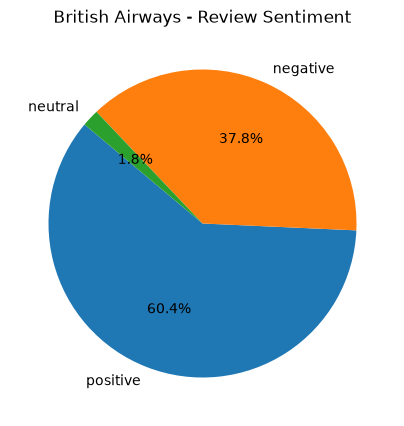

In [14]:
#piechart of positive/ negative / neutral Sentiment
import matplotlib.pyplot as plt

# Count sentiments in your specific order
counts = df['sentiment'].value_counts().reindex(["positive", "negative", "neutral"])

# Plot the pie chart
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140)
plt.title("British Airways - Review Sentiment")
plt.show()


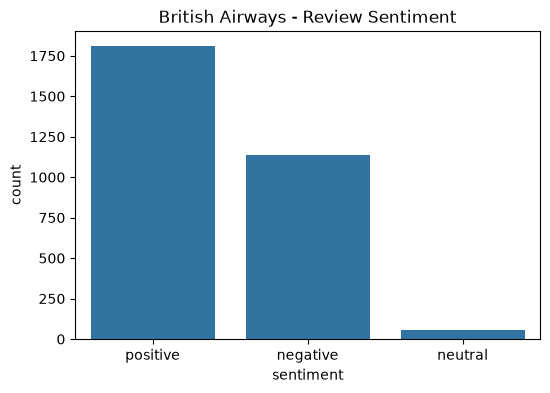

In [15]:
# Countplot how many reviews are positive/ negative / neutral
plt.figure(figsize=(6,4))
sns.countplot(x="sentiment",data=df, order=["positive","negative","neutral"])
plt.title("British Airways - Review Sentiment")
plt.show()

In [16]:
# Drop neutral — too few samples (1.8%) to learn from
df = df[df["sentiment"] != "neutral"].reset_index(drop=True)
df["sentiment"].value_counts()

sentiment
positive    1812
negative    1134
Name: count, dtype: int64

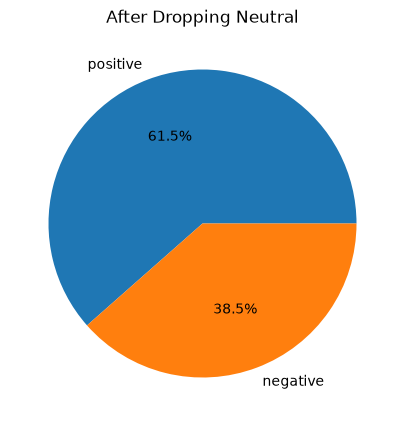

In [17]:
# Pie chart after drop
counts = df["sentiment"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%")
plt.title("After Dropping Neutral")
plt.show()

## Sentiment Analysis

In [18]:
# --------Sentiment Analysis - Model Building------

# Import needed libraries from sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [19]:
X = df["cleaned"]   # Features
y = df["sentiment"]  # Target/Label

In [20]:
# -------Vectorization------
# TfidfVectorizer = Turns text to numbers
# TF-IDF gives importance score to each word
# Keep only 5000 most important words
tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(X)

## Model Training & Evaluation

In [21]:
# split data into 80% train and 20% test to evaluate model on unseen data
# X_tfidf = numbers, y = label
X_train, X_test, y_train, y_test =train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

In [22]:
# Fit a Logistic Regression Model
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

              precision    recall  f1-score   support

    negative       0.80      0.62      0.70       239
    positive       0.78      0.89      0.83       351

    accuracy                           0.78       590
   macro avg       0.79      0.76      0.77       590
weighted avg       0.79      0.78      0.78       590



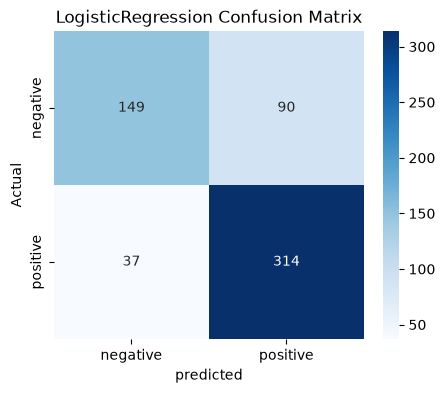

In [23]:
from sklearn.metrics import confusion_matrix

pred = log_reg.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred) #build confusion mtrix

# plot heatmap of LogisticRegression confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("LogisticRegression Confusion Matrix")
plt.show()

In [24]:
# Training a multinomial Naive Bayes model
from sklearn.naive_bayes import MultinomialNB
mult_nb = MultinomialNB()
mult_nb.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[ 895.,1461.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.97,-0.48]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](2,)","['negative','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5000)","[[0.42,1. ,1.06,...,0. ,0.18,2.68], [0.18,0.56,1.21,...,0.46,0.35,2.22]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5000)","[[-8.95,-8.61,-8.58,...,-9.3 ,-9.14,-8. ], [-9.45,-9.17,-8.82,...,-9.24,-9.31,-8.45]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


              precision    recall  f1-score   support

    negative       0.74      0.45      0.56       239
    positive       0.70      0.89      0.79       351

    accuracy                           0.71       590
   macro avg       0.72      0.67      0.67       590
weighted avg       0.72      0.71      0.70       590



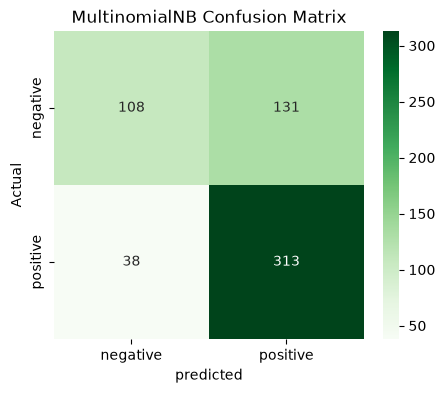

In [25]:
from sklearn.metrics import confusion_matrix
pred = mult_nb.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred) #build confusion mtrix

# plot heatmap of MultinomialNB confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("MultinomialNB Confusion Matrix")
plt.show()

In [26]:
# Training support vector classifier model
from sklearn.svm import SVC
svc_model = SVC()
svc_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


              precision    recall  f1-score   support

    negative       0.79      0.69      0.74       239
    positive       0.81      0.88      0.84       351

    accuracy                           0.80       590
   macro avg       0.80      0.78      0.79       590
weighted avg       0.80      0.80      0.80       590



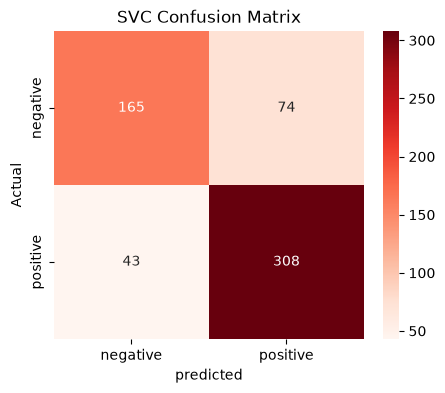

In [27]:
from sklearn.metrics import confusion_matrix
pred = svc_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred) #build confusion mtrix

# plot heatmap of SVC confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("SVC Confusion Matrix")
plt.show()

In [28]:
# training LinearSVC model
from sklearn.svm import LinearSVC
lin_svc = LinearSVC()
lin_svc.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

              precision    recall  f1-score   support

    negative       0.81      0.73      0.77       239
    positive       0.83      0.88      0.85       351

    accuracy                           0.82       590
   macro avg       0.82      0.81      0.81       590
weighted avg       0.82      0.82      0.82       590



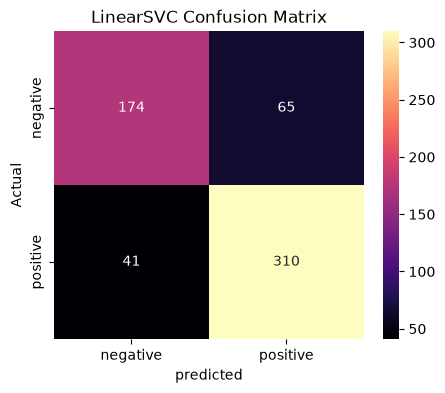

In [29]:
from sklearn.metrics import confusion_matrix
pred = lin_svc.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(y_test, pred) #build confusion mtrix

# plot heatmap of LinearSVC confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="magma",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("LinearSVC Confusion Matrix")
plt.show()

In [30]:
# Import FunctionTransformer — to wrap a plain Python function as a pipeline step
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

In [31]:
# Wrapper so clean_text can handle a list of reviews (pipeline passes many at once)
def clean_series(texts):
    return [clean_text(t) for t in texts]

# Pipeline: cleaner → vectorizer → model
# Pipeline now cleans raw text internally, so training and prediction use the same steps
pipe = Pipeline([
    ("clean",     FunctionTransformer(clean_series)),   # Step 1: clean raw text
    ("tfidf",     TfidfVectorizer(max_features=5000)),  # Step 2: convert text to numbers
    ("log_model", LogisticRegression(                    # Step 3: classify
        class_weight="balanced",                         # Handle positive/negative imbalance
        max_iter=1000                                    # More iterations so it converges
    ))
])

In [32]:
# IMPORTANT: fit on RAW reviews, not cleaned
# The pipeline will clean them itself in step 1
# This prevents the bug where training saw cleaned text but predictions saw raw text
pipe.fit(df["reviews"], df["sentiment"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clean', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cle...001E89F425BC0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True


In [33]:
pipe.predict(["The flight was delayed and baggage lost"])

array(['negative'], dtype=object)

In [34]:
pipe.predict(["Amazing crew, love it"])

array(['positive'], dtype=object)

## Model Deployment

In [35]:
import joblib

joblib.dump(pipe, "sentiment_model.pkl")
print("Model saved as sentiment_model.pkl")

Model saved as sentiment_model.pkl
